# 🫀 PTB-XL ECG Classifier → ONNX → Browser (Kaggle)

Trains a **small 1D-CNN** (~0.1 M parameters) on **all 21,799 PTB-XL ECGs** to recognise five diagnostic superclasses,
exports it to **ONNX**, and writes a ready-to-publish **GitHub Pages** site (`docs/`) where the model runs entirely
in the visitor's browser. No server is needed.

**Before Run All**
1. Accelerator **GPU T4** · Internet **On**.
2. Data: nothing to do. If a PTB-XL copy is attached under *Add Input* it is used; otherwise it downloads from
   PhysioNet (open access, 1.7 GB) once.
3. Optional but recommended: Add-ons → **Google Cloud Services** → tick **Cloud Storage**, and set `project_id`. Then
   the prepared data (.npz) and all checkpoints live in your bucket, and a stopped session resumes mid-epoch.

At the end, download **`results_for_github.zip`** and unzip it at the repo root. It contains `docs/` (the web demo),
`models/` (`.pth` + `.onnx`) and `results/` (report and figures). PTB-XL is CC BY 4.0, so all of it may be published.

## 1 · Setup
BigQuery/GCS clients (already on Kaggle; this only fills gaps) and GPU check.

In [1]:
!pip install -q google-cloud-bigquery google-cloud-bigquery-storage google-cloud-storage db-dtypes pyarrow wfdb onnx onnxruntime 2>&1 | tail -1
import torch, platform
print("python", platform.python_version(), "| torch", torch.__version__, "| GPU:",
   torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none (CPU)")

tensorflow 2.19.0 requires protobuf!=4.21.0,!=4.21.1,!=4.21.2,!=4.21.3,!=4.21.4,!=4.21.5,<6.0.0dev,>=3.20.3, but you have protobuf 6.33.6 which is incompatible.
python 3.12.12 | torch 2.10.0+cu128 | GPU: Tesla T4


## 2 · Project code
These cells write the package to `/kaggle/working/repo`. No need to edit them; the steps further down call this code.

In [2]:
!mkdir -p /kaggle/working/repo/src

In [3]:
%%writefile /kaggle/working/repo/src/__init__.py
"""package"""


Writing /kaggle/working/repo/src/__init__.py


In [4]:
%%writefile /kaggle/working/repo/src/bq.py
"""SQL -> Parquet, cached in the bucket.

* BigQuery: `EXPORT DATA` writes the query result straight into your GCS bucket as Parquet. That is much faster
  than pulling millions of rows through the API, and the result stays cached there: a re-run (or a new Kaggle
  session) skips BigQuery completely and only downloads the files.
* Tests: the same BigQuery SQL is transpiled to DuckDB (sqlglot) and run on small synthetic tables.

SQL uses placeholders such as `{hosp}` / `{icu}` / `{derived}` / `{eicu}` for the PhysioNet datasets.
Only numeric / text columns are exported (times are turned into hours inside SQL), so Parquet types are simple.
"""
from __future__ import annotations

import hashlib
import json
import logging
import time
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import pandas as pd

log = logging.getLogger(__name__)


class BigQuerySource:
    kind = "bigquery"

    def __init__(self, cfg, store, datasets: dict):
        """datasets: {placeholder: (override, [candidate dataset names], probe_table)}"""
        from .gcp import bq_client, resolve_dataset
        self.client = bq_client(cfg.project_id)
        self.store = store
        self.ds = {k: resolve_dataset(self.client, o, c, p) for k, (o, c, p) in datasets.items()}
        for k, v in self.ds.items():
            log.info("{%s} -> %s", k, v)

    def fmt(self, sql: str) -> str:
        return sql.format(**{k: f"`{v}`" for k, v in self.ds.items()})

    def export(self, sql: str, key: str):
        from .store import GCSStore
        sql = self.fmt(sql)
        if isinstance(self.store, GCSStore):
            uri = self.store.uri(f"{key}/part-*.parquet")
            q = f"EXPORT DATA OPTIONS(uri='{uri}', format='PARQUET', compression='SNAPPY', overwrite=true) AS\n{sql}"
            try:
                job = self.client.query(q)
                job.result()
                log.info("BigQuery processed %.2f GB -> %s", (job.total_bytes_processed or 0) / 1e9, uri)
                return
            except Exception as e:                     # e.g. the token may not write to GCS -> stream instead
                log.warning("EXPORT DATA failed (%s). Streaming the result through the Storage API instead.",
                            str(e)[:200])
        self._stream(sql, key)

    def _stream(self, sql: str, key: str, rows_per_file: int = 2_000_000):
        """Run the query and write the result in Parquet parts (Storage Read API if allowed, else REST pages)."""
        import pyarrow as pa
        import pyarrow.parquet as pq
        job = self.client.query(sql)
        it = job.result(page_size=100_000)
        log.info("BigQuery processed %.2f GB, %s rows", (job.total_bytes_processed or 0) / 1e9, it.total_rows)
        bqs = None
        try:
            from google.cloud import bigquery_storage
            from .gcp import credentials
            bqs = bigquery_storage.BigQueryReadClient(credentials=credentials("bigquery"))
        except Exception:
            pass
        tmp = Path("/tmp") / key.replace("/", "_")
        tmp.mkdir(parents=True, exist_ok=True)
        buf, n, part = [], 0, 0

        def flush():
            nonlocal buf, n, part
            if buf:
                f = tmp / f"part-{part:05d}.parquet"
                pq.write_table(pa.concat_tables(buf, promote_options="default"), f, compression="snappy")
                self.store.put(f, f"{key}/{f.name}")
                f.unlink()
                buf, n, part = [], 0, part + 1
        try:
            batches = it.to_arrow_iterable(bqstorage_client=bqs)
        except TypeError:
            batches = it.to_arrow_iterable()
        for b in batches:
            t = b if isinstance(b, pa.Table) else pa.Table.from_batches([b])
            buf.append(t)
            n += t.num_rows
            if n >= rows_per_file:
                flush()
        flush()
        if part == 0:                                   # empty result: still write one (empty) file
            f = tmp / "part-00000.parquet"
            it.to_arrow().to_pandas().to_parquet(f, index=False)
            self.store.put(f, f"{key}/{f.name}")

    def df(self, sql: str) -> pd.DataFrame:
        from .gcp import query_df
        return query_df(self.client, self.fmt(sql))


class DuckDBSource:
    """Runs the BigQuery SQL on DuckDB (unit tests / CI with synthetic tables)."""
    kind = "duckdb"

    def __init__(self, con, schemas: dict, store):
        self.con, self.ds, self.store = con, schemas, store

    def fmt(self, sql: str) -> str:
        import sqlglot
        return sqlglot.transpile(sql.format(**self.ds), read="bigquery", write="duckdb")[0]

    def export(self, sql: str, key: str):
        tmp = Path(self.store.uri(f"{key}/part-000.parquet"))
        tmp.parent.mkdir(parents=True, exist_ok=True)
        self.con.execute(f"COPY ({self.fmt(sql)}) TO '{tmp.as_posix()}' (FORMAT PARQUET)")

    def df(self, sql: str) -> pd.DataFrame:
        return self.con.execute(self.fmt(sql)).df()


def materialize(src, store, name: str, sql: str, cache_dir) -> list[Path]:
    """Run `sql` once (result cached in the bucket under data/<name>-<hash>/) and return local Parquet paths."""
    key = f"data/{name}-{hashlib.sha1(src.fmt(sql).encode()).hexdigest()[:10]}"
    if store.exists(f"{key}/_SUCCESS"):
        log.info("[%s] cached in bucket (%s) -> BigQuery skipped", name, store.uri(key))
    else:
        t = time.time()
        src.export(sql, key)
        store.put_text(json.dumps({"seconds": round(time.time() - t, 1)}), f"{key}/_SUCCESS")
        log.info("[%s] query done in %.0f s", name, time.time() - t)
    parts = sorted(k for k in store.list(key) if k.endswith(".parquet"))
    local = Path(cache_dir) / key
    local.mkdir(parents=True, exist_ok=True)

    def fetch(k):
        dst = local / Path(k).name
        if not dst.exists():
            store.get(k, dst)
        return dst
    with ThreadPoolExecutor(8) as ex:
        paths = list(ex.map(fetch, parts))
    log.info("[%s] %d parquet file(s) ready in %s", name, len(paths), local)
    return paths


def read(paths, columns=None) -> pd.DataFrame:
    import pyarrow.parquet as pq
    import pyarrow as pa
    tabs = [pq.read_table(p, columns=columns) for p in paths]
    tabs = [t for t in tabs if t.num_rows] or tabs[:1]
    return pa.concat_tables(tabs, promote_options="default").to_pandas() if tabs else pd.DataFrame()


def n_rows(paths) -> int:
    import pyarrow.parquet as pq
    return sum(pq.ParquetFile(p).metadata.num_rows for p in paths)


Writing /kaggle/working/repo/src/bq.py


In [5]:
%%writefile /kaggle/working/repo/src/config.py
from __future__ import annotations

from dataclasses import asdict, dataclass


@dataclass
class Config:
    # --- data: PTB-XL v1.0.3 (open access, CC BY 4.0), all 21,799 records, 100 Hz ---
    data_dir: str = ""                    # "" = search /kaggle/input for ptbxl_database.csv, else download from PhysioNet
    download_url: str = "https://physionet.org/content/ptb-xl/get-zip/1.0.3/"
    sampling_rate: int = 100              # 100 Hz x 10 s = 1000 samples per lead (small enough for the browser)
    task: str = "superdiagnostic"         # 5 classes: NORM, MI, STTC, CD, HYP (multi-label)
    train_folds: tuple = (1, 2, 3, 4, 5, 6, 7, 8)   # official split: 9 = validation, 10 = test
    val_fold: int = 9
    test_fold: int = 10
    seed: int = 42

    # --- compact 1D-CNN ---
    widths: tuple = (32, 64, 96, 128)
    kernel: int = 7
    dropout: float = 0.2
    batch_size: int = 128
    lr: float = 3e-3
    epochs: int = 60
    patience: int = 10
    augment: bool = True                  # amplitude scaling, baseline shift, noise, time shift

    # --- evaluation / export ---
    n_boot: int = 500
    demo_per_class: int = 3               # example ECGs (test fold) shipped with the web demo
    opset: int = 17

    # --- outputs + checkpoints ---
    work_dir: str = "/kaggle/working/ecg"
    cache_dir: str = "/tmp/ecg_cache"
    project_id: str = ""                  # GCS bucket for data cache + checkpoints ("" = local only, no resume across sessions)
    bucket: str = ""
    bucket_location: str = "US"
    gcs_prefix: str = "ptbxl-ecg-browser"
    run_name: str = "main"
    local_store: str = ""
    ckpt_every_min: float = 5.0
    device: str = ""

    def to_dict(self):
        return asdict(self)


Writing /kaggle/working/repo/src/config.py


In [6]:
%%writefile /kaggle/working/repo/src/data.py
"""PTB-XL loading: find the dataset (Kaggle input or PhysioNet download), read all records with wfdb once, and cache
one compact .npz (float16) in the bucket so later sessions skip the 1.7 GB download and the 21,799 file reads."""
from __future__ import annotations

import ast
import io
import logging
import zipfile
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import numpy as np
import pandas as pd

log = logging.getLogger(__name__)
CLASSES = ["NORM", "MI", "STTC", "CD", "HYP"]
CLASS_NAMES = {"NORM": "Normal ECG", "MI": "Myocardial infarction", "STTC": "ST/T change",
               "CD": "Conduction disturbance", "HYP": "Hypertrophy"}


def locate(cfg) -> Path:
    if cfg.data_dir and (Path(cfg.data_dir) / "ptbxl_database.csv").exists():
        return Path(cfg.data_dir)
    for root in (Path("/kaggle/input"), Path(cfg.cache_dir)):
        if root.exists():
            hits = sorted(root.rglob("ptbxl_database.csv"))
            if hits:
                return hits[0].parent
    return download(cfg)


def download(cfg) -> Path:
    """PhysioNet zip (1.7 GB). Only the CSVs and the records of the chosen sampling rate are extracted."""
    import requests
    out = Path(cfg.cache_dir) / "ptbxl"
    z = Path(cfg.cache_dir) / "ptbxl.zip"
    z.parent.mkdir(parents=True, exist_ok=True)
    if not z.exists():
        log.info("downloading PTB-XL from %s (1.7 GB) ...", cfg.download_url)
        with requests.get(cfg.download_url, stream=True, timeout=120) as r:
            r.raise_for_status()
            tmp = z.with_suffix(".part")
            with open(tmp, "wb") as f:
                for chunk in r.iter_content(1 << 22):
                    f.write(chunk)
            tmp.replace(z)
    folder = "records100/" if cfg.sampling_rate == 100 else "records500/"
    with zipfile.ZipFile(z) as zf:
        names = [n for n in zf.namelist() if n.endswith(("ptbxl_database.csv", "scp_statements.csv")) or folder in n]
        zf.extractall(out, members=names)
    return next(out.rglob("ptbxl_database.csv")).parent


def labels(db: pd.DataFrame, scp: pd.DataFrame) -> np.ndarray:
    diag = scp[scp.diagnostic == 1]
    Y = np.zeros((len(db), len(CLASSES)), np.uint8)
    for i, codes in enumerate(db.scp_codes):
        for code in ast.literal_eval(codes) if isinstance(codes, str) else codes:
            if code in diag.index:
                c = diag.loc[code, "diagnostic_class"]
                if c in CLASSES:
                    Y[i, CLASSES.index(c)] = 1
    return Y


def build(root: Path, cfg) -> dict:
    import wfdb
    db = pd.read_csv(root / "ptbxl_database.csv", index_col="ecg_id")
    scp = pd.read_csv(root / "scp_statements.csv", index_col=0)
    col = "filename_lr" if cfg.sampling_rate == 100 else "filename_hr"
    files = [str(root / f) for f in db[col]]

    def rd(f):
        sig, meta = wfdb.rdsamp(f)
        return sig.astype(np.float16), meta["sig_name"]
    with ThreadPoolExecutor(16) as ex:
        res = list(ex.map(rd, files))
    X = np.stack([r[0] for r in res])
    return dict(X=X, Y=labels(db, scp), fold=db.strat_fold.to_numpy(np.int8), ecg_id=db.index.to_numpy(np.int32),
                leads=np.array(res[0][1]), classes=np.array(CLASSES))


def load(cfg, store) -> dict:
    key = f"data/ptbxl-{cfg.sampling_rate}hz-v1.0.3.npz"
    local = Path(cfg.cache_dir) / Path(key).name
    if not local.exists() and store.exists(key):
        log.info("PTB-XL cache found in bucket -> download skipped")
        store.get(key, local)
    if local.exists():
        d = dict(np.load(local, allow_pickle=False))
    else:
        root = locate(cfg)
        log.info("reading all PTB-XL records from %s (once)", root)
        d = build(root, cfg)
        local.parent.mkdir(parents=True, exist_ok=True)
        np.savez(local, **d)
        store.put(local, key)
    log.info("PTB-XL: %d records, X %s, labelled %d", len(d["Y"]), d["X"].shape, int((d["Y"].sum(1) > 0).sum()))
    return d


def splits(d: dict, cfg) -> dict:
    """Official folds; records without any superclass label are dropped (as in Strodthoff et al., 2020)."""
    ok = d["Y"].sum(1) > 0
    f = d["fold"]
    return {"train": np.flatnonzero(ok & np.isin(f, cfg.train_folds)), "val": np.flatnonzero(ok & (f == cfg.val_fold)),
            "test": np.flatnonzero(ok & (f == cfg.test_fold))}


Writing /kaggle/working/repo/src/data.py


In [7]:
%%writefile /kaggle/working/repo/src/evaluate.py
from __future__ import annotations

import numpy as np
import pandas as pd
from sklearn.metrics import average_precision_score, f1_score, roc_auc_score

from .data import CLASS_NAMES, CLASSES
from .metrics import best_f1_threshold


def thresholds(Yv, Pv) -> np.ndarray:
    """Per-class decision threshold = best F1 on the validation fold."""
    return np.array([best_f1_threshold(Yv[:, j], Pv[:, j]) for j in range(Yv.shape[1])])


def per_class(Y, P, thr) -> pd.DataFrame:
    rows = []
    for j, c in enumerate(CLASSES):
        y, p = Y[:, j], P[:, j]
        rows.append(dict(cls=c, name=CLASS_NAMES[c], n=int(len(y)), positives=int(y.sum()), auroc=roc_auc_score(y, p),
                         auprc=average_precision_score(y, p), threshold=float(thr[j]),
                         f1=f1_score(y, p >= thr[j], zero_division=0),
                         sensitivity=float(((p >= thr[j]) & (y == 1)).sum() / max(y.sum(), 1)),
                         specificity=float(((p < thr[j]) & (y == 0)).sum() / max((y == 0).sum(), 1))))
    return pd.DataFrame(rows)


def macro_ci(Y, P, n=500, seed=0):
    r = np.random.default_rng(seed)
    vals = []
    for _ in range(n):
        i = r.integers(0, len(Y), len(Y))
        a = [roc_auc_score(Y[i, j], P[i, j]) for j in range(Y.shape[1]) if 0 < Y[i, j].sum() < len(i)]
        if a:
            vals.append(np.mean(a))
    return (float(np.percentile(vals, 2.5)), float(np.percentile(vals, 97.5))) if vals else (np.nan, np.nan)


def plot_roc(Y, P, path):
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    from sklearn.metrics import roc_curve
    fig, ax = plt.subplots(figsize=(5.2, 4.8))
    for j, c in enumerate(CLASSES):
        f, t, _ = roc_curve(Y[:, j], P[:, j])
        ax.plot(f, t, label=f"{c} ({roc_auc_score(Y[:, j], P[:, j]):.3f})")
    ax.plot([0, 1], [0, 1], "k--", lw=.7)
    ax.set(xlabel="False positive rate", ylabel="True positive rate", title="PTB-XL test fold — ROC per class")
    ax.legend(fontsize=8)
    ax.grid(alpha=.3)
    fig.tight_layout()
    fig.savefig(path, dpi=150)
    plt.close(fig)


def plot_example(x, leads, probs, thr, true, path, fs=100):
    """One test ECG (public PTB-XL) with the model's output — figure for the README."""
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    t = np.arange(x.shape[0]) / fs
    fig, axes = plt.subplots(12, 1, figsize=(9, 9), sharex=True)
    for i, ax in enumerate(axes):
        ax.plot(t, x[:, i], lw=.8, c="k")
        ax.set_ylabel(leads[i], rotation=0, labelpad=14, fontsize=7)
        ax.set_yticks([])
        ax.grid(alpha=.25)
    axes[-1].set_xlabel("seconds")
    txt = "  ".join(f"{c}: {p:.2f}{' ✓' if p >= th else ''}" for c, p, th in zip(CLASSES, probs, thr))
    fig.suptitle(f"model: {txt}\ntrue: {', '.join(c for c, y in zip(CLASSES, true) if y)}", fontsize=8)
    fig.tight_layout()
    fig.savefig(path, dpi=130)
    plt.close(fig)


Writing /kaggle/working/repo/src/evaluate.py


In [8]:
%%writefile /kaggle/working/repo/src/export.py
"""ONNX export (+ onnxruntime parity check and CPU latency) and the files the GitHub Pages demo needs."""
from __future__ import annotations

import json
import time
from pathlib import Path

import numpy as np
import torch

from .data import CLASS_NAMES, CLASSES
from .model import Probabilities


def to_onnx(model, path: Path, n_leads: int, n_samples: int, opset: int = 17) -> Path:
    m = Probabilities(model).cpu().eval()
    dummy = torch.zeros(1, n_leads, n_samples)
    kw = dict(input_names=["ecg"], output_names=["probabilities"], opset_version=opset,
              dynamic_axes={"ecg": {0: "batch"}, "probabilities": {0: "batch"}})
    import warnings
    warnings.filterwarnings("ignore", category=DeprecationWarning)     # classic exporter: no onnxscript needed
    try:
        torch.onnx.export(m, dummy, str(path), dynamo=False, **kw)
    except TypeError:                                          # older torch: no `dynamo` argument
        torch.onnx.export(m, dummy, str(path), **kw)
    return path


def check(model, path: Path, X: np.ndarray) -> dict:
    """Max |torch - onnxruntime| on real ECGs and single-ECG CPU latency."""
    import onnxruntime as ort
    sess = ort.InferenceSession(str(path), providers=["CPUExecutionProvider"])
    x = X.astype(np.float32).transpose(0, 2, 1)
    with torch.no_grad():
        ref = Probabilities(model).cpu().eval()(torch.from_numpy(x)).numpy()
    got = sess.run(None, {"ecg": x})[0]
    one = x[:1]
    sess.run(None, {"ecg": one})
    t = time.time()
    for _ in range(20):
        sess.run(None, {"ecg": one})
    return {"max_abs_diff": float(np.abs(ref - got).max()), "cpu_ms_per_ecg": round((time.time() - t) / 20 * 1000, 2),
            "onnx_kb": round(path.stat().st_size / 1024, 1)}


def demo_assets(out: Path, d, test_idx, P_test, thr, summary: dict, per_class_rows, cfg):
    """docs/meta.json + docs/samples.json: a few PTB-XL test ECGs (CC BY 4.0) to try in the browser."""
    out.mkdir(parents=True, exist_ok=True)
    Y = d["Y"]
    picked = []
    for j in range(len(CLASSES)):                               # confident, correct examples of each class
        cand = [i for i in np.argsort(-P_test[:, j]) if Y[test_idx[i], j] == 1 and P_test[i, j] >= thr[j]]
        picked += [i for i in cand if i not in picked][: cfg.demo_per_class]
    samples = []
    for i in picked:
        r = test_idx[i]
        samples.append({"ecg_id": int(d["ecg_id"][r]), "true": [c for c, y in zip(CLASSES, Y[r]) if y],
                        "signal": np.round(d["X"][r].astype(np.float32).T, 3).tolist()})   # [12][T] in mV
    meta = {"classes": CLASSES, "names": [CLASS_NAMES[c] for c in CLASSES], "thresholds": [round(float(t), 4) for t in thr],
            "leads": [str(x) for x in d["leads"]], "fs": cfg.sampling_rate, "n_samples": int(d["X"].shape[1]),
            "test": {"macro_auroc": summary["macro_auroc"], "macro_auroc_ci": summary["macro_auroc_ci"],
                     "per_class": [{k: (round(v, 4) if isinstance(v, float) else v) for k, v in r.items()}
                                   for r in per_class_rows]},
            "model": {"params": summary["params"], "onnx_kb": summary["onnx"]["onnx_kb"]},
            "source": "PTB-XL v1.0.3 (Wagner et al., 2020/2022), CC BY 4.0"}
    (out / "meta.json").write_text(json.dumps(meta, indent=1))
    (out / "samples.json").write_text(json.dumps(samples, separators=(",", ":")))
    return len(samples)


Writing /kaggle/working/repo/src/export.py


In [9]:
%%writefile /kaggle/working/repo/src/gcp.py
"""BigQuery helpers. Works with Kaggle's "Google Cloud Services" add-on
(linked account) and with normal ADC credentials elsewhere."""
from __future__ import annotations

import json
import logging
import os
from pathlib import Path

log = logging.getLogger(__name__)
SOURCE_PROJECT = "physionet-data"


def _kaggle_integrations() -> str:
    return os.environ.get("KAGGLE_KERNEL_INTEGRATIONS", "")


def credentials(target: str):
    """Credentials for 'bigquery' or 'gcs'.
    On Kaggle: the account attached in Add-ons -> Google Cloud Services (passed explicitly, so we never
    fall back to the GCE metadata server). Elsewhere: Application Default Credentials (None)."""
    if "KAGGLE_USER_SECRETS_TOKEN" not in os.environ:
        return None                                   # not on Kaggle -> ADC
    want = {"bigquery": "BIGQUERY", "gcs": "GCS"}[target]
    have = [x.upper() for x in _kaggle_integrations().split(":") if x]
    if want in have:
        from kaggle_secrets import GcpTarget
        try:
            from kaggle_gcp import KaggleKernelCredentials
        except ImportError:                           # minimal re-implementation
            from google.auth import credentials as gac
            from kaggle_secrets import UserSecretsClient

            class KaggleKernelCredentials(gac.Credentials):
                def __init__(self, target):
                    super().__init__()
                    self.target = target

                def refresh(self, request):
                    self.token, self.expiry = UserSecretsClient()._get_access_token(self.target)
        return KaggleKernelCredentials(target=GcpTarget[want])
    try:                                              # Add-ons -> "Google Cloud SDK" also works
        from google.oauth2.credentials import Credentials
        from kaggle_secrets import UserSecretsClient
        info = json.loads(UserSecretsClient().get_gcloud_credential())
        log.info("Using Google Cloud SDK add-on credential for %s", target)
        return Credentials.from_authorized_user_info(info)
    except Exception:
        pass
    raise RuntimeError(
        f"Kaggle has no {want} integration attached (KAGGLE_KERNEL_INTEGRATIONS='{_kaggle_integrations()}').\n"
        "Fix: Add-ons -> Google Cloud Services -> attach your Google account and tick BOTH 'BigQuery' and "
        "'Cloud Storage' -> Save -> then Run -> Restart & clear outputs -> Run All.")


def validate_project_id(project_id: str) -> str:
    pid = (project_id or "").strip()
    if not pid or "YOUR_" in pid.upper() or " " in pid:
        raise ValueError(
            f"cfg.project_id='{project_id}' is not a real GCP project ID.\n"
            "Find it: console.cloud.google.com -> project picker (top bar) -> copy the 'ID' column "
            "(e.g. 'mimic-research-123456', NOT the display name). Use the same Google account/project "
            "that is attached in Kaggle Add-ons and has billing/BigQuery enabled.")
    return pid


def check_access(project_id: str, probes=()):
    """Quick pre-flight check printed in the notebook."""
    try:
        validate_project_id(project_id)
        print("project_id:", project_id, "OK")
    except ValueError as e:
        print("project_id: FAILED ->", e)
        return
    print("Kaggle integrations:", _kaggle_integrations() or "(none)")
    for t in ("bigquery", "gcs"):
        try:
            c = credentials(t)
            if c is not None:
                from google.auth.transport.requests import Request
                c.refresh(Request())
            print(f"  {t:8s}: OK")
        except Exception as e:
            print(f"  {t:8s}: FAILED -> {e}")
            return
    try:
        client = bq_client(project_id)
        from google.cloud import bigquery
        client.query("SELECT 1", job_config=bigquery.QueryJobConfig(dry_run=True))
        print("  BigQuery project/billing: OK")
    except Exception as e:
        print("  BigQuery project/billing: FAILED ->", str(e)[:300])
        return
    for t in probes:
        ok = _dry_run_ok(client, f"SELECT 1 FROM `{SOURCE_PROJECT}.{t}` LIMIT 1")
        print(f"  PhysioNet {t}: {'OK' if ok else 'not readable (other version name is tried automatically)'}")


def bq_client(project_id: str):
    from google.cloud import bigquery
    project_id = validate_project_id(project_id)
    return bigquery.Client(project=project_id, credentials=credentials("bigquery"))


def _dry_run_ok(client, sql: str) -> bool:
    from google.api_core import exceptions as gexc
    from google.cloud import bigquery
    try:
        client.query(sql, job_config=bigquery.QueryJobConfig(dry_run=True, use_query_cache=False))
        return True
    except (gexc.NotFound, gexc.Forbidden, gexc.BadRequest):
        return False            # dataset absent or no PhysioNet access -> try next candidate


def resolve_dataset(client, override: str, candidates: list[str], probe_table: str) -> str:
    """Return 'physionet-data.<dataset>' that the account can read (free dry-run probe)."""
    names = [override] if override else candidates
    for name in names:
        fq = name if "." in name else f"{SOURCE_PROJECT}.{name}"
        if _dry_run_ok(client, f"SELECT 1 FROM `{fq}.{probe_table}` LIMIT 1"):
            log.info("Using dataset %s", fq)
            return fq
    raise RuntimeError(
        f"None of {names} is readable (probe table '{probe_table}'). Open BigQuery console -> "
        f"'{SOURCE_PROJECT}' and set the dataset name in the config.")


def query_df(client, sql: str):
    job = client.query(sql)
    job.result()
    log.info("BigQuery processed %.2f GB", (job.total_bytes_processed or 0) / 1e9)
    try:
        return job.to_dataframe(create_bqstorage_client=True)
    except Exception as e:  # Storage Read API not permitted -> REST fallback
        log.warning("BQ Storage API unavailable (%s). Falling back to REST download.", type(e).__name__)
        return job.result().to_dataframe(create_bqstorage_client=False)


Writing /kaggle/working/repo/src/gcp.py


In [10]:
%%writefile /kaggle/working/repo/src/metrics.py
"""Binary-classification metrics, bootstrap CIs, plots and small-cell suppression (PhysioNet rule of thumb:
never publish a count below 10)."""
from __future__ import annotations

import numpy as np
import pandas as pd
from sklearn.metrics import (average_precision_score, brier_score_loss, f1_score, precision_score, recall_score,
                             roc_auc_score, roc_curve)

MIN_CELL = 10


def ece(y, p, bins: int = 10) -> float:
    y, p = np.asarray(y, float), np.asarray(p, float)
    edges = np.quantile(p, np.linspace(0, 1, bins + 1))
    idx = np.clip(np.searchsorted(edges, p, side="right") - 1, 0, bins - 1)
    e = 0.0
    for b in range(bins):
        m = idx == b
        if m.any():
            e += m.mean() * abs(y[m].mean() - p[m].mean())
    return float(e)


def binary(y, p, thr: float | None = None) -> dict:
    y, p = np.asarray(y), np.asarray(p, float)
    out = dict(n=len(y), n_pos=int(y.sum()), prevalence=float(y.mean()) if len(y) else np.nan)
    if 0 < y.sum() < len(y):
        out.update(auroc=roc_auc_score(y, p), auprc=average_precision_score(y, p), brier=brier_score_loss(y, p),
                   ece=ece(y, p))
    if thr is not None:
        pr = p >= thr
        out.update(threshold=thr, f1=f1_score(y, pr, zero_division=0), precision=precision_score(y, pr, zero_division=0),
                   recall=recall_score(y, pr, zero_division=0),
                   specificity=float(((~pr) & (y == 0)).sum() / max((y == 0).sum(), 1)))
    return out


def bootstrap_ci(y, p, fn=roc_auc_score, n: int = 200, seed: int = 0, max_n: int = 200_000):
    """Percentile 95% CI. Large sets are subsampled to `max_n` per resample (CI is then slightly conservative)."""
    y, p = np.asarray(y), np.asarray(p)
    if n <= 0 or y.sum() == 0 or y.sum() == len(y):
        return (np.nan, np.nan)
    r = np.random.default_rng(seed)
    k = min(len(y), max_n)
    vals = []
    for _ in range(n):
        i = r.integers(0, len(y), k)
        if 0 < y[i].sum() < k:
            vals.append(fn(y[i], p[i]))
    return (float(np.percentile(vals, 2.5)), float(np.percentile(vals, 97.5))) if vals else (np.nan, np.nan)


def best_f1_threshold(y, p) -> float:
    ts = np.unique(np.quantile(p, np.linspace(0.01, 0.99, 199)))
    return float(ts[int(np.argmax([f1_score(y, p >= t, zero_division=0) for t in ts]))])


def suppress(df: pd.DataFrame, count_cols=("n", "n_pos"), min_n: int = MIN_CELL) -> pd.DataFrame:
    """Drop rows whose counts could identify few patients (n < 10). Zero positives is not a small cell."""
    df = df.copy()
    keep = np.ones(len(df), bool)
    for c in count_cols:
        if c in df:
            v = pd.to_numeric(df[c], errors="coerce").fillna(0).to_numpy()
            keep &= (v == 0) | (v >= min_n)
    return df[keep].reset_index(drop=True)


def plot_roc_pr(curves: dict, path, pos_label="positive"):
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    from sklearn.metrics import precision_recall_curve
    fig, ax = plt.subplots(1, 2, figsize=(10, 4.2))
    for name, (y, p) in curves.items():
        y, p = np.asarray(y), np.asarray(p)
        if not (0 < y.sum() < len(y)):
            continue
        fpr, tpr, _ = roc_curve(y, p)
        pr, rc, _ = precision_recall_curve(y, p)
        k = max(1, len(fpr) // 2000)
        ax[0].plot(fpr[::k], tpr[::k], label=f"{name} ({roc_auc_score(y, p):.3f})")
        k = max(1, len(rc) // 2000)
        ax[1].plot(rc[::k], pr[::k], label=f"{name} ({average_precision_score(y, p):.3f})")
    ax[0].plot([0, 1], [0, 1], "k--", lw=.7)
    ax[0].set(xlabel="False positive rate", ylabel="True positive rate", title="ROC (AUROC)")
    ax[1].set(xlabel=f"Recall ({pos_label})", ylabel=f"Precision ({pos_label})", title="Precision-recall (AUPRC)")
    for a in ax:
        a.legend(fontsize=7)
        a.grid(alpha=.3)
    fig.tight_layout()
    fig.savefig(path, dpi=150)
    plt.close(fig)


def plot_calibration(curves: dict, path, bins: int = 10):
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(figsize=(4.8, 4.4))
    for name, (y, p) in curves.items():
        y, p = np.asarray(y, float), np.asarray(p, float)
        q = np.quantile(p, np.linspace(0, 1, bins + 1))
        idx = np.clip(np.searchsorted(q, p, side="right") - 1, 0, bins - 1)
        xs = [p[idx == b].mean() for b in range(bins) if (idx == b).sum() >= MIN_CELL]
        ys = [y[idx == b].mean() for b in range(bins) if (idx == b).sum() >= MIN_CELL]
        ax.plot(xs, ys, "o-", ms=3, label=name)
    ax.plot([0, 1], [0, 1], "k--", lw=.7)
    ax.set(xlabel="Predicted probability", ylabel="Observed rate", title="Calibration (deciles)")
    ax.legend(fontsize=7)
    ax.grid(alpha=.3)
    fig.tight_layout()
    fig.savefig(path, dpi=150)
    plt.close(fig)


def md(df: pd.DataFrame, floatfmt="{:.3f}") -> str:
    if df is None or not len(df):
        return "–"

    def f(v):
        if isinstance(v, (float, np.floating)):
            return "–" if np.isnan(v) else floatfmt.format(v)
        if isinstance(v, (int, np.integer)):
            return f"{v:,}"
        return str(v)
    return "\n".join(["| " + " | ".join(map(str, df.columns)) + " |", "|" + "---|" * len(df.columns)] +
                     ["| " + " | ".join(f(v) for v in r) + " |" for r in df.itertuples(index=False)])


Writing /kaggle/working/repo/src/metrics.py


In [11]:
%%writefile /kaggle/working/repo/src/model.py
"""Compact residual 1D-CNN with depthwise-separable convolutions (~0.1 M parameters, < 1 MB as ONNX).
Per-lead normalisation is a buffer INSIDE the model, so the browser feeds raw millivolts: input [batch, 12, 1000]."""
from __future__ import annotations

import torch
import torch.nn as nn


class SepBlock(nn.Module):
    def __init__(self, cin, cout, k, stride, dropout):
        super().__init__()
        self.body = nn.Sequential(
            nn.Conv1d(cin, cin, k, stride=stride, padding=k // 2, groups=cin, bias=False), nn.BatchNorm1d(cin),
            nn.ReLU(), nn.Conv1d(cin, cout, 1, bias=False), nn.BatchNorm1d(cout), nn.ReLU(), nn.Dropout(dropout),
            nn.Conv1d(cout, cout, k, padding=k // 2, groups=cout, bias=False), nn.BatchNorm1d(cout),
            nn.Conv1d(cout, cout, 1, bias=False), nn.BatchNorm1d(cout))
        self.skip = nn.Sequential(nn.Conv1d(cin, cout, 1, stride=stride, bias=False), nn.BatchNorm1d(cout)) \
            if (cin != cout or stride != 1) else nn.Identity()
        self.act = nn.ReLU()

    def forward(self, x):
        return self.act(self.body(x) + self.skip(x))


class ECGNet(nn.Module):
    def __init__(self, n_leads=12, n_classes=5, widths=(32, 64, 96, 128), k=7, dropout=0.2):
        super().__init__()
        self.register_buffer("mu", torch.zeros(1, n_leads, 1))
        self.register_buffer("sd", torch.ones(1, n_leads, 1))
        self.stem = nn.Sequential(nn.Conv1d(n_leads, widths[0], 15, stride=2, padding=7, bias=False),
                                  nn.BatchNorm1d(widths[0]), nn.ReLU())
        blocks, c = [], widths[0]
        for w in widths:
            blocks.append(SepBlock(c, w, k, 2, dropout))
            c = w
        self.blocks = nn.Sequential(*blocks)
        self.head = nn.Sequential(nn.Dropout(dropout), nn.Linear(2 * c, n_classes))

    def forward(self, x):                        # x: raw mV [B, 12, T]
        x = (x - self.mu) / self.sd
        h = self.blocks(self.stem(x))
        return self.head(torch.cat([h.mean(-1), h.amax(-1)], 1))


class Probabilities(nn.Module):
    """Export wrapper: sigmoid probabilities instead of logits."""

    def __init__(self, m):
        super().__init__()
        self.m = m

    def forward(self, x):
        return torch.sigmoid(self.m(x))


def n_params(m) -> int:
    return sum(p.numel() for p in m.parameters())


Writing /kaggle/working/repo/src/model.py


In [12]:
%%writefile /kaggle/working/repo/src/pipeline.py
"""PTB-XL (all records) -> compact 1D-CNN (resumable) -> test-fold evaluation -> ONNX (+ parity check) ->
GitHub Pages demo assets (docs/) -> report. Open data: weights, ONNX and examples may be published."""
from __future__ import annotations

import hashlib
import json
import logging
import shutil
import time
from pathlib import Path

import numpy as np
import pandas as pd
import torch

from . import data, evaluate, export
from .config import Config
from .metrics import md
from .model import n_params
from .store import LocalStore
from .train import macro_auc, predict, train
from .trainer import history

log = logging.getLogger("ecg")


def run(cfg: Config) -> dict:
    t0 = time.time()
    logging.basicConfig(level=logging.INFO, format="%(asctime)s %(levelname)s %(name)s: %(message)s", force=True)
    for noisy in ("google", "urllib3", "matplotlib"):
        logging.getLogger(noisy).setLevel(logging.WARNING)
    out = Path(cfg.work_dir)
    for sub in ("figures", "models", "results", "docs"):
        (out / sub).mkdir(parents=True, exist_ok=True)
    if cfg.project_id or cfg.local_store:
        from .store import make_store
        store = make_store(cfg)
    else:                                   # no bucket: works, but a new Kaggle session cannot resume
        store = LocalStore(out / "local_bucket", cfg.gcs_prefix)
    device = torch.device(cfg.device or ("cuda" if torch.cuda.is_available() else "cpu"))
    log.info("device: %s | checkpoints: %s", device, store.uri())

    # %% Load PTB-XL | All 21,799 records at 100 Hz. First run: Kaggle input or PhysioNet download (1.7 GB), read once with wfdb and cached as one .npz in your bucket; later runs skip all of that.
    # show: split_tab
    d = data.load(cfg, store)
    sp = data.splits(d, cfg)
    split_tab = pd.DataFrame([{"part": k, "records": len(v), **{c: int(d["Y"][v, j].sum()) for j, c in enumerate(data.CLASSES)}}
                              for k, v in sp.items()])

    # %% Train the 1D-CNN (resumable mid-epoch) | Official folds 1–8 train, 9 validation. Model, optimizer, scheduler and the position inside the epoch are saved every few minutes.
    # show: history(st, "val_macro_auroc")
    fp = hashlib.sha1(json.dumps([len(d["Y"]), list(cfg.widths), cfg.kernel, cfg.dropout, cfg.lr, cfg.batch_size,
                                  cfg.augment, cfg.seed]).encode()).hexdigest()[:8]
    model, st = train(cfg, d, sp, device, store, f"ckpt/{cfg.run_name}-{cfg.sampling_rate}hz-{fp}")
    log.info("parameters: %s", f"{n_params(model):,}")

    # %% Evaluate on the test fold | Fold 10 (human-validated labels). Per-class thresholds = best F1 on fold 9.
    # show: pc
    Pv, Pt = predict(model, d["X"], sp["val"], device), predict(model, d["X"], sp["test"], device)
    Yv, Yt = d["Y"][sp["val"]], d["Y"][sp["test"]]
    thr = evaluate.thresholds(Yv, Pv)
    pc = evaluate.per_class(Yt, Pt, thr)
    ci = evaluate.macro_ci(Yt, Pt, cfg.n_boot, cfg.seed)
    evaluate.plot_roc(Yt, Pt, out / "figures" / "roc_test.png")
    i0 = int(np.argmax(Pt[:, 1] * Yt[:, 1])) if Yt[:, 1].any() else 0
    evaluate.plot_example(d["X"][sp["test"][i0]].astype(np.float32), d["leads"], Pt[i0], thr, Yt[i0],
                          out / "figures" / "example_ecg.png", cfg.sampling_rate)

    # %% Export to ONNX | Probabilities = sigmoid inside the graph; per-lead normalisation is inside the model, so the browser sends raw mV. Checked against onnxruntime.
    # show: pd.Series(onnx_info)
    onnx_path = export.to_onnx(model, out / "docs" / "model.onnx", d["X"].shape[2], d["X"].shape[1], cfg.opset)
    onnx_info = export.check(model, onnx_path, d["X"][sp["test"][:64]])
    model.to(device)

    # %% Web demo assets + report | `docs/` = GitHub Pages site (model.onnx, meta.json, samples.json). `.pth` is included: PTB-XL is open data (CC BY 4.0).
    # show: pd.Series({"demo examples": n_demo, "macro AUROC (test)": round(summary["macro_auroc"], 4)})
    summary = dict(records=len(d["Y"]), split=split_tab.to_dict("records"), params=n_params(model),
                   macro_auroc=macro_auc(Yt, Pt), macro_auroc_ci=list(ci), best_epoch=st.best_epoch,
                   per_class=pc.to_dict("records"), onnx=onnx_info, runtime_min=round((time.time() - t0) / 60, 1),
                   config=cfg.to_dict())
    n_demo = export.demo_assets(out / "docs", d, sp["test"], Pt, thr, summary, pc.to_dict("records"), cfg)
    torch.save({"state_dict": {k: v.cpu() for k, v in model.state_dict().items()}, "classes": data.CLASSES,
                "leads": [str(x) for x in d["leads"]], "fs": cfg.sampling_rate, "widths": list(cfg.widths),
                "kernel": cfg.kernel, "dropout": cfg.dropout, "thresholds": thr.tolist()}, out / "models" / "ecgnet.pth")
    shutil.copy(onnx_path, out / "models" / "ecgnet.onnx")
    (out / "results" / "metrics.json").write_text(json.dumps(summary, indent=1, default=float))
    from .report import build as build_report
    build_report(out, pc, split_tab, summary)
    store.put_dir(out / "results", f"runs/{cfg.run_name}/results")
    store.put_dir(out / "models", f"runs/{cfg.run_name}/models")
    log.info("DONE in %.1f min | test macro AUROC %.4f", summary["runtime_min"], summary["macro_auroc"])
    return summary


Writing /kaggle/working/repo/src/pipeline.py


In [13]:
%%writefile /kaggle/working/repo/src/report.py
from __future__ import annotations

import shutil
from pathlib import Path

from .metrics import md


def build(out: Path, pc, split_tab, s: dict) -> str:
    res = out / "results"
    (res / "figures").mkdir(parents=True, exist_ok=True)
    for f in (out / "figures").glob("*.png"):
        shutil.copy(f, res / "figures" / f.name)
    pc.to_csv(res / "per_class.csv", index=False)
    lo, hi = s["macro_auroc_ci"]
    o = s["onnx"]
    text = f"""# Results — PTB-XL 5-class ECG classifier (browser-sized)

**Data:** PTB-XL v1.0.3, all {s['records']:,} records, 12 leads, 10 s at {s['config']['sampling_rate']} Hz.
Official split: folds 1–8 train, 9 validation, 10 test (human-validated). Task: diagnostic superclasses
(NORM, MI, STTC, CD, HYP), multi-label.

**Model:** compact residual 1D-CNN with depthwise-separable convolutions, **{s['params']:,} parameters**,
ONNX **{o['onnx_kb']} KB**, {o['cpu_ms_per_ecg']} ms per ECG on one CPU core (onnxruntime). ONNX vs PyTorch max
difference: {o['max_abs_diff']:.2e}.

## Test fold
**Macro AUROC {s['macro_auroc']:.4f}** (95% bootstrap CI {lo:.4f}–{hi:.4f}) · best epoch {s['best_epoch']}.

{md(pc.drop(columns=['n']))}

![ROC](figures/roc_test.png)

## Data
{md(__import__('pandas').DataFrame(s['split']))}

## Example (test fold)
![example](figures/example_ecg.png)

---
Runtime {s['runtime_min']} min. Reference point: Strodthoff et al. (2020) report macro AUROC ≈ 0.93 for much
larger models (e.g. xresnet1d101) on the same split; this model trades a little accuracy for being small enough to
run in a web page. Not a medical device.
"""
    (res / "REPORT.md").write_text(text, encoding="utf-8")
    return text


Writing /kaggle/working/repo/src/report.py


In [14]:
%%writefile /kaggle/working/repo/src/store.py
"""Checkpoint store: a private GCS bucket (auto-created) or a local folder (tests / no GCP).
Everything needed to resume after a Kaggle session stops lives here."""
from __future__ import annotations

import logging
import re
import shutil
from pathlib import Path

log = logging.getLogger(__name__)


def default_bucket_name(project_id: str) -> str:
    name = re.sub(r"[^a-z0-9-]", "-", f"{project_id}-mimic-ckpt".lower()).strip("-")
    return name[:63]


class GCSStore:
    def __init__(self, project_id: str, bucket: str, prefix: str, location: str = "US"):
        from google.cloud import storage

        from .gcp import credentials
        self.client = storage.Client(project=project_id, credentials=credentials("gcs"))
        self.name = (bucket or default_bucket_name(project_id)).replace("gs://", "").strip("/")
        self.prefix = prefix.strip("/")
        self.bucket = self._ensure(project_id, location)

    def _ensure(self, project_id, location):
        from google.api_core import exceptions as gexc
        b = self.client.bucket(self.name)
        try:
            if b.exists():
                return b
        except gexc.Forbidden:
            return b           # exists but owned elsewhere / no get permission; writes will tell
        try:
            b.iam_configuration.uniform_bucket_level_access_enabled = True
            b.iam_configuration.public_access_prevention = "enforced"   # never public
            b = self.client.create_bucket(b, project=project_id, location=location)
            log.info("Created private bucket gs://%s (%s)", self.name, location)
        except gexc.Conflict:
            raise RuntimeError(f"Bucket name '{self.name}' is taken globally. Set cfg.bucket to another name.")
        except Exception as e:
            raise RuntimeError(
                f"Could not create bucket gs://{self.name} ({e}). Create it once in Cloud Shell:\n"
                f"  gcloud storage buckets create gs://{self.name} --project={project_id} --location={location} "
                f"--uniform-bucket-level-access --public-access-prevention\nthen set cfg.bucket='{self.name}'.")
        return b

    def uri(self, key=""):
        return f"gs://{self.name}/{self.prefix}/{key}".rstrip("/")

    def _k(self, key):
        return f"{self.prefix}/{key}"

    def put(self, local, key):
        self.bucket.blob(self._k(key)).upload_from_filename(str(local), timeout=600)

    def get(self, key, local) -> bool:
        bl = self.bucket.blob(self._k(key))
        if not bl.exists():
            return False
        Path(local).parent.mkdir(parents=True, exist_ok=True)
        tmp = Path(str(local) + ".part")
        bl.download_to_filename(str(tmp), timeout=600)
        tmp.replace(local)                        # never leave a half-downloaded file behind
        return True

    def exists(self, key) -> bool:
        return self.bucket.blob(self._k(key)).exists()

    def list(self, sub) -> list[str]:
        p = self._k(sub).rstrip("/") + "/"
        return [b.name[len(self.prefix) + 1:] for b in self.client.list_blobs(self.bucket, prefix=p)]

    def put_text(self, text, key):
        self.bucket.blob(self._k(key)).upload_from_string(text)

    def get_text(self, key):
        bl = self.bucket.blob(self._k(key))
        return bl.download_as_text() if bl.exists() else None

    def put_dir(self, local_dir, sub):
        n = 0
        for p in sorted(Path(local_dir).rglob("*")):
            if p.is_file():
                self.put(p, f"{sub.strip('/')}/{p.relative_to(local_dir).as_posix()}")
                n += 1
        log.info("Uploaded %d files -> %s", n, self.uri(sub))


class LocalStore:
    """Same interface backed by a folder (unit tests, or running without GCP)."""

    def __init__(self, root, prefix=""):
        self.root = Path(root) / prefix
        self.root.mkdir(parents=True, exist_ok=True)
        self.name = str(self.root)

    def uri(self, key=""):
        return str(self.root / key)

    def put(self, local, key):
        dst = self.root / key
        dst.parent.mkdir(parents=True, exist_ok=True)
        shutil.copyfile(local, dst)

    def get(self, key, local) -> bool:
        src = self.root / key
        if not src.exists():
            return False
        Path(local).parent.mkdir(parents=True, exist_ok=True)
        if Path(local).resolve() != src.resolve():
            shutil.copyfile(src, local)
        return True

    def exists(self, key) -> bool:
        return (self.root / key).exists()

    def list(self, sub) -> list[str]:
        d = self.root / sub
        return [p.relative_to(self.root).as_posix() for p in d.rglob("*") if p.is_file()] if d.exists() else []

    def put_text(self, text, key):
        dst = self.root / key
        dst.parent.mkdir(parents=True, exist_ok=True)
        dst.write_text(text)

    def get_text(self, key):
        f = self.root / key
        return f.read_text() if f.exists() else None

    def put_dir(self, local_dir, sub):
        for p in Path(local_dir).rglob("*"):
            if p.is_file():
                self.put(p, f"{sub.strip('/')}/{p.relative_to(local_dir).as_posix()}")


def make_store(cfg):
    if getattr(cfg, "local_store", ""):
        return LocalStore(cfg.local_store, cfg.gcs_prefix)
    from .gcp import validate_project_id
    cfg.project_id = validate_project_id(cfg.project_id)
    s = GCSStore(cfg.project_id, cfg.bucket, cfg.gcs_prefix, cfg.bucket_location)
    cfg.bucket = s.name
    log.info("Checkpoints -> %s", s.uri())
    return s


Writing /kaggle/working/repo/src/store.py


In [15]:
%%writefile /kaggle/working/repo/src/train.py
"""Training with the resumable trainer (mid-epoch checkpoints in the bucket) + GPU augmentation."""
from __future__ import annotations

import numpy as np
import torch
import torch.nn.functional as F
from sklearn.metrics import roc_auc_score

from .model import ECGNet
from .trainer import Checkpointer, TensorBatches, cosine_warmup, fit


def augment(x):
    """x [B, 12, T] in mV: amplitude scaling, baseline offset, gaussian noise, circular time shift."""
    B = x.shape[0]
    x = x * (1 + 0.1 * torch.randn(B, 1, 1, device=x.device))
    x = x + 0.05 * torch.randn(B, x.shape[1], 1, device=x.device)
    x = x + 0.01 * torch.randn_like(x)
    shift = int(torch.randint(-50, 51, (1,)).item())
    return torch.roll(x, shift, dims=-1)


@torch.no_grad()
def predict(model, X, idx, device, bs=1024) -> np.ndarray:
    model.eval()
    out = []
    for s in range(0, len(idx), bs):
        x = torch.from_numpy(X[idx[s:s + bs]].astype(np.float32)).to(device).transpose(1, 2)
        out.append(torch.sigmoid(model(x)).cpu().numpy())
    return np.concatenate(out) if out else np.zeros((0, 5))


def macro_auc(Y, P):
    a = [roc_auc_score(Y[:, j], P[:, j]) for j in range(Y.shape[1]) if 0 < Y[:, j].sum() < len(Y)]
    return float(np.mean(a)) if a else float("nan")


def train(cfg, d, sp, device, store, key):
    X, Y = d["X"], d["Y"].astype(np.float32)
    tr, va = sp["train"], sp["val"]
    torch.manual_seed(cfg.seed)
    model = ECGNet(X.shape[2], Y.shape[1], cfg.widths, cfg.kernel, cfg.dropout).to(device)
    xt = X[tr].astype(np.float32)
    model.mu.copy_(torch.tensor(xt.mean((0, 1))).view(1, -1, 1))          # per-lead statistics of the training set
    model.sd.copy_(torch.tensor(xt.std((0, 1)) + 1e-6).view(1, -1, 1))
    del xt
    batches = TensorBatches({"x": X[tr], "y": Y[tr]}, cfg.batch_size, cfg.seed, device)
    opt = torch.optim.AdamW(model.parameters(), lr=cfg.lr, weight_decay=1e-2)
    sched = cosine_warmup(opt, cfg.epochs * len(batches), warmup=0.05)

    def loss_fn(m, b):
        x = b["x"].float().transpose(1, 2)
        if cfg.augment:
            x = augment(x)
        return F.binary_cross_entropy_with_logits(m(x), b["y"])

    def evaluate(m):
        return {"val_macro_auroc": macro_auc(Y[va], predict(m, X, va, device))}
    return fit(model, opt, epochs=cfg.epochs, batches=batches, loss_fn=loss_fn, evaluate=evaluate, sched=sched,
               ckpt=Checkpointer(store, key, f"{cfg.work_dir}/ckpt/ecgnet"), metric="val_macro_auroc",
               patience=cfg.patience, ckpt_every_min=cfg.ckpt_every_min, log_every=0)


Writing /kaggle/working/repo/src/train.py


In [16]:
%%writefile /kaggle/working/repo/src/trainer.py
"""Resumable PyTorch training.

Everything needed to continue is saved as `last.pt` (model, optimizer, scheduler, RNG states, epoch AND the step
inside the epoch) every `ckpt_every_min` minutes and at the end of every epoch, locally and in the bucket.
The batch order of an epoch depends only on (seed, epoch), so a new Kaggle session skips exactly the batches that
were already done and continues in the middle of the epoch. `best.pt` keeps the best validation weights.
"""
from __future__ import annotations

import logging
import math
import time
import uuid
from dataclasses import asdict, dataclass, field
from pathlib import Path

import numpy as np
import pandas as pd
import torch

log = logging.getLogger(__name__)


class Checkpointer:
    def __init__(self, store, key: str, local_dir):
        self.store, self.key, self.dir = store, key.strip("/"), Path(local_dir)
        self.dir.mkdir(parents=True, exist_ok=True)

    def save(self, obj, name: str):
        f = self.dir / name
        tmp = f.with_suffix(".tmp")
        torch.save(obj, tmp)
        tmp.replace(f)
        if self.store is not None:
            self.store.put(f, f"{self.key}/{name}")

    def load(self, name: str):
        f = self.dir / name
        if not f.exists() and self.store is not None:
            self.store.get(f"{self.key}/{name}", f)
        return torch.load(f, map_location="cpu", weights_only=False) if f.exists() else None


@dataclass
class State:
    epoch: int = 0                 # finished epochs
    step: int = 0                  # finished steps inside the current epoch
    loss_sum: float = 0.0
    loss_n: int = 0
    best: float = -math.inf
    best_epoch: int = 0
    bad_epochs: int = 0
    done: bool = False
    history: list = field(default_factory=list)


def _rng_state():
    s = {"torch": torch.get_rng_state(), "numpy": np.random.get_state()}
    if torch.cuda.is_available():
        s["cuda"] = torch.cuda.get_rng_state_all()
    return s


def _set_rng(s):
    torch.set_rng_state(s["torch"])
    np.random.set_state(s["numpy"])
    if "cuda" in s and torch.cuda.is_available():
        torch.cuda.set_rng_state_all(s["cuda"])


class TensorBatches:
    """Mini-batches from in-memory arrays. Order = f(seed, epoch) -> exact mid-epoch resume.
    With `on_device=True` the arrays are copied to the GPU once (fast for tabular data)."""

    def __init__(self, arrays: dict, batch_size: int, seed: int, device, on_device: bool = True, index=None,
                 tensors: dict | None = None):
        """`index`: use only these rows (no copy of the big arrays). `tensors`: already-built torch tensors."""
        self.bs, self.seed, self.device = batch_size, seed, torch.device(device)
        tgt = self.device if on_device else torch.device("cpu")
        def to_t(v):                                   # numpy array OR torch tensor (CPU or GPU)
            if isinstance(v, torch.Tensor):
                return v.to(tgt)
            return torch.as_tensor(np.ascontiguousarray(v)).to(tgt)
        self.t = tensors if tensors is not None else {k: to_t(v) for k, v in arrays.items()}
        some = next(iter(self.t.values()))
        self.index = None if index is None else torch.as_tensor(np.asarray(index, dtype=np.int64)).to(some.device)
        self.n = len(some) if index is None else len(self.index)
        self._perm = (None, None)

    def __len__(self):
        return max(1, -(-self.n // self.bs))

    def __call__(self, epoch: int, step: int) -> dict:
        if self._perm[0] != epoch:
            self._perm = (epoch, torch.from_numpy(np.random.default_rng(self.seed + epoch).permutation(self.n)))
        idx = self._perm[1][step * self.bs:(step + 1) * self.bs]
        some = next(iter(self.t.values()))
        idx = idx.to(some.device)
        if self.index is not None:
            idx = self.index[idx]
        return {k: v[idx].to(self.device, non_blocking=True) for k, v in self.t.items()}


def fit(model, opt, *, epochs: int, batches, loss_fn, evaluate, ckpt: Checkpointer, metric: str,
        sched=None, patience: int = 0, ckpt_every_min: float = 10.0, grad_clip: float = 1.0, log_every: int = 500):
    """Train with resume. `evaluate(model) -> dict` must contain `metric` (higher is better).
    Returns (model with best weights, State)."""
    session = uuid.uuid4().hex[:6]
    st = State()
    last = ckpt.load("last.pt")
    if last is not None:
        model.load_state_dict(last["model"])
        opt.load_state_dict(last["opt"])
        if sched is not None and last.get("sched") is not None:
            sched.load_state_dict(last["sched"])
        st = State(**last["state"])
        _set_rng(last["rng"])
        log.info("RESUME from bucket checkpoint: %d epoch(s) done, %d/%d steps of epoch %d already done",
                 st.epoch, st.step, len(batches), st.epoch + 1)

    def save_last():
        ckpt.save({"model": model.state_dict(), "opt": opt.state_dict(),
                   "sched": sched.state_dict() if sched is not None else None,
                   "state": asdict(st), "rng": _rng_state()}, "last.pt")

    t_save = time.time()
    while not st.done and st.epoch < epochs:
        model.train()
        t_ep = time.time()
        for step in range(st.step, len(batches)):
            b = batches(st.epoch, step)
            loss = loss_fn(model, b)
            opt.zero_grad(set_to_none=True)
            loss.backward()
            if grad_clip:
                torch.nn.utils.clip_grad_norm_(model.parameters(), grad_clip)
            opt.step()
            if sched is not None:
                sched.step()
            st.step, st.loss_sum, st.loss_n = step + 1, st.loss_sum + float(loss.detach()), st.loss_n + 1
            if log_every and (step + 1) % log_every == 0:
                log.info("epoch %d step %d/%d loss %.4f", st.epoch + 1, step + 1, len(batches), st.loss_sum / st.loss_n)
            if time.time() - t_save > ckpt_every_min * 60:
                save_last()
                t_save = time.time()
                log.info("mid-epoch checkpoint saved (epoch %d, step %d)", st.epoch + 1, st.step)
        model.eval()
        with torch.no_grad():
            val = {k: float(v) for k, v in evaluate(model).items()}
        row = {"epoch": st.epoch + 1, "train_loss": st.loss_sum / max(st.loss_n, 1), **val,
               "minutes": round((time.time() - t_ep) / 60, 2), "session": session}
        st.history.append(row)
        if val[metric] > st.best:
            st.best, st.best_epoch, st.bad_epochs = val[metric], st.epoch + 1, 0
            ckpt.save({"model": model.state_dict(), "epoch": st.epoch + 1, metric: val[metric]}, "best.pt")
        else:
            st.bad_epochs += 1
        log.info("epoch %d: %s", st.epoch + 1, ", ".join(f"{k}={v:.4f}" for k, v in row.items()
                                                       if isinstance(v, float)))
        st.epoch, st.step, st.loss_sum, st.loss_n = st.epoch + 1, 0, 0.0, 0
        if patience and st.bad_epochs >= patience:
            log.info("early stop: no %s improvement for %d epochs", metric, patience)
            st.done = True
        save_last()
        t_save = time.time()
    st.done = True
    save_last()
    best = ckpt.load("best.pt")
    if best is not None:
        model.load_state_dict(best["model"])
    model.eval()
    st.session = session
    return model, st


def history(st: State, metric: str) -> pd.DataFrame:
    """One row per epoch; `source` tells whether the epoch was trained now or restored from the bucket."""
    df = pd.DataFrame(st.history)
    if not len(df):
        return pd.DataFrame({"info": ["no epochs"]})
    cur = getattr(st, "session", None)
    df["source"] = np.where(df.session == cur, "this session", "checkpoint")
    df["best"] = np.where(df.epoch == st.best_epoch, "★", "")
    return df.drop(columns="session")


def cosine_warmup(opt, total_steps: int, warmup: float = 0.03):
    w = max(1, int(total_steps * warmup))

    def f(s):
        if s < w:
            return (s + 1) / w
        return 0.5 * (1 + math.cos(math.pi * min(1.0, (s - w) / max(1, total_steps - w))))
    return torch.optim.lr_scheduler.LambdaLR(opt, f)


Writing /kaggle/working/repo/src/trainer.py


## 3 · Config
Change only this cell.

In [17]:
import sys
sys.path.insert(0, "/kaggle/working/repo")
from src.config import Config

cfg = Config(
    project_id="mimic-cxr-training",   # <-- GCP project for the checkpoint bucket ("" = no bucket, no cross-session resume)
    work_dir="/kaggle/working/ecg",
    epochs=60, batch_size=128, lr=3e-3,
    widths=(32, 64, 96, 128),          # model size (bigger = more accurate, heavier web page)
    run_name="main",                   # change to start a fresh set of checkpoints
)
cfg

Config(data_dir='', download_url='https://physionet.org/content/ptb-xl/get-zip/1.0.3/', sampling_rate=100, task='superdiagnostic', train_folds=(1, 2, 3, 4, 5, 6, 7, 8), val_fold=9, test_fold=10, seed=42, widths=(32, 64, 96, 128), kernel=7, dropout=0.2, batch_size=128, lr=0.003, epochs=60, patience=10, augment=True, n_boot=500, demo_per_class=3, opset=17, work_dir='/kaggle/working/ecg', cache_dir='/tmp/ecg_cache', project_id='mimic-cxr-training', bucket='', bucket_location='US', gcs_prefix='ptbxl-ecg-browser', run_name='main', local_store='', ckpt_every_min=5.0, device='')

## 4 · Pre-flight check
GPU, and the Cloud Storage bucket (only if `project_id` is set).

In [18]:
import torch
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none (CPU, slower)")
if cfg.project_id:
    from src.store import make_store
    s = make_store(cfg)
    print("bucket OK:", s.uri())
else:
    print("no project_id: checkpoints stay in /kaggle/working only")

GPU: Tesla T4
bucket OK: gs://mimic-cxr-training-mimic-ckpt/ptbxl-ecg-browser


## 5 · Load the pipeline
Imports the project code written above. The cells below are the steps of `src/pipeline.py::run()`, one per cell.

In [19]:
import sys, time
from IPython.display import display
for _m in [m for m in list(sys.modules) if m == "src" or m.startswith("src.")]:
    del sys.modules[_m]                       # always use the freshly written code (no stale imports)
import src.pipeline as _pipeline
globals().update({k: v for k, v in vars(_pipeline).items() if not k.startswith("__")})   # helpers + imports


class StopRun(Exception):
    """Raised on purpose (e.g. no GPU yet / paused): Run All again later to continue."""


def _stop(result):
    print(result)
    raise StopRun(result.get("status", "stopped") if isinstance(result, dict) else str(result))


## 6 · Start
Logging, folders and the checkpoint store.

In [20]:
t0 = time.time()
logging.basicConfig(level=logging.INFO, format="%(asctime)s %(levelname)s %(name)s: %(message)s", force=True)
for noisy in ("google", "urllib3", "matplotlib"):
    logging.getLogger(noisy).setLevel(logging.WARNING)
out = Path(cfg.work_dir)
for sub in ("figures", "models", "results", "docs"):
    (out / sub).mkdir(parents=True, exist_ok=True)
if cfg.project_id or cfg.local_store:
    from src.store import make_store
    store = make_store(cfg)
else:                                   # no bucket: works, but a new Kaggle session cannot resume
    store = LocalStore(out / "local_bucket", cfg.gcs_prefix)
device = torch.device(cfg.device or ("cuda" if torch.cuda.is_available() else "cpu"))
log.info("device: %s | checkpoints: %s", device, store.uri())

2026-11-26 14:57:51,726 INFO src.gcp: Using Google Cloud SDK add-on credential for gcs
2026-11-26 14:57:51,830 INFO src.store: Checkpoints -> gs://mimic-cxr-training-mimic-ckpt/ptbxl-ecg-browser
2026-11-26 14:57:51,831 INFO ecg: device: cuda | checkpoints: gs://mimic-cxr-training-mimic-ckpt/ptbxl-ecg-browser


## 7 · Load PTB-XL
All 21,799 records at 100 Hz. First run: Kaggle input or PhysioNet download (1.7 GB), read once with wfdb and cached as one .npz in your bucket; later runs skip all of that.

In [21]:
d = data.load(cfg, store)
sp = data.splits(d, cfg)
split_tab = pd.DataFrame([{"part": k, "records": len(v), **{c: int(d["Y"][v, j].sum()) for j, c in enumerate(data.CLASSES)}}
                          for k, v in sp.items()])
display(split_tab)

2026-11-26 14:57:51,890 INFO src.data: downloading PTB-XL from https://physionet.org/content/ptb-xl/get-zip/1.0.3/ (1.7 GB) ...
2026-11-26 14:58:58,441 INFO src.data: reading all PTB-XL records from /tmp/ecg_cache/ptbxl/ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.3 (once)
2026-11-26 15:00:16,249 INFO src.data: PTB-XL: 21799 records, X (21799, 1000, 12), labelled 21388


,part,records,NORM,MI,STTC,CD,HYP
0,train,17084,7596,4379,4186,3907,2119
1,val,2146,955,540,528,495,268
2,test,2158,963,550,521,496,262


## 8 · Train the 1D-CNN (resumable mid-epoch)
Official folds 1–8 train, 9 validation. Model, optimizer, scheduler and the position inside the epoch are saved every few minutes.

In [22]:
fp = hashlib.sha1(json.dumps([len(d["Y"]), list(cfg.widths), cfg.kernel, cfg.dropout, cfg.lr, cfg.batch_size,
                              cfg.augment, cfg.seed]).encode()).hexdigest()[:8]
model, st = train(cfg, d, sp, device, store, f"ckpt/{cfg.run_name}-{cfg.sampling_rate}hz-{fp}")
log.info("parameters: %s", f"{n_params(model):,}")
display(history(st, "val_macro_auroc"))

2026-11-26 15:00:26,625 INFO src.trainer: epoch 1: train_loss=0.6016, val_macro_auroc=0.8341, minutes=0.0600
2026-11-26 15:00:28,848 INFO src.trainer: epoch 2: train_loss=0.3669, val_macro_auroc=0.8862, minutes=0.0300
2026-11-26 15:00:31,104 INFO src.trainer: epoch 3: train_loss=0.3280, val_macro_auroc=0.9012, minutes=0.0300
2026-11-26 15:00:33,418 INFO src.trainer: epoch 4: train_loss=0.3089, val_macro_auroc=0.9087, minutes=0.0300
2026-11-26 15:00:35,747 INFO src.trainer: epoch 5: train_loss=0.2977, val_macro_auroc=0.9152, minutes=0.0300
2026-11-26 15:00:37,795 INFO src.trainer: epoch 6: train_loss=0.2886, val_macro_auroc=0.9120, minutes=0.0300
2026-11-26 15:00:40,062 INFO src.trainer: epoch 7: train_loss=0.2812, val_macro_auroc=0.9162, minutes=0.0300
2026-11-26 15:00:42,221 INFO src.trainer: epoch 8: train_loss=0.2773, val_macro_auroc=0.9126, minutes=0.0300
2026-11-26 15:00:44,469 INFO src.trainer: epoch 9: train_loss=0.2723, val_macro_auroc=0.9120, minutes=0.0300
2026-11-26 15:00:46

,epoch,train_loss,val_macro_auroc,minutes,source,best
0,1,0.601623,0.834122,0.06,this session,
1,2,0.366916,0.886182,0.03,this session,
2,3,0.327999,0.901164,0.03,this session,
3,4,0.308856,0.908726,0.03,this session,
4,5,0.297746,0.915249,0.03,this session,
5,6,0.288634,0.911996,0.03,this session,
6,7,0.281177,0.916155,0.03,this session,
7,8,0.277314,0.912642,0.03,this session,
8,9,0.272324,0.911961,0.03,this session,
9,10,0.269543,0.917305,0.03,this session,


## 9 · Evaluate on the test fold
Fold 10 (human-validated labels). Per-class thresholds = best F1 on fold 9.

In [23]:
Pv, Pt = predict(model, d["X"], sp["val"], device), predict(model, d["X"], sp["test"], device)
Yv, Yt = d["Y"][sp["val"]], d["Y"][sp["test"]]
thr = evaluate.thresholds(Yv, Pv)
pc = evaluate.per_class(Yt, Pt, thr)
ci = evaluate.macro_ci(Yt, Pt, cfg.n_boot, cfg.seed)
evaluate.plot_roc(Yt, Pt, out / "figures" / "roc_test.png")
i0 = int(np.argmax(Pt[:, 1] * Yt[:, 1])) if Yt[:, 1].any() else 0
evaluate.plot_example(d["X"][sp["test"][i0]].astype(np.float32), d["leads"], Pt[i0], thr, Yt[i0],
                      out / "figures" / "example_ecg.png", cfg.sampling_rate)
display(pc)

,cls,name,n,positives,auroc,auprc,threshold,f1,sensitivity,specificity
0,NORM,Normal ECG,2158,963,0.946629,0.927242,0.746204,0.858740,0.877466,0.866109
1,MI,Myocardial infarction,2158,550,0.923830,0.836057,0.239795,0.738772,0.732727,0.914179
2,STTC,ST/T change,2158,521,0.938492,0.840439,0.364853,0.776364,0.819578,0.907147
3,CD,Conduction disturbance,2158,496,0.922287,0.850019,0.415868,0.759259,0.743952,0.935620
4,HYP,Hypertrophy,2158,262,0.897957,0.652346,0.214034,0.594306,0.637405,0.929852


## 10 · Export to ONNX
Probabilities = sigmoid inside the graph; per-lead normalisation is inside the model, so the browser sends raw mV. Checked against onnxruntime.

In [24]:
onnx_path = export.to_onnx(model, out / "docs" / "model.onnx", d["X"].shape[2], d["X"].shape[1], cfg.opset)
onnx_info = export.check(model, onnx_path, d["X"][sp["test"][:64]])
model.to(device)
display(pd.Series(onnx_info))

max_abs_diff      3.874302e-07
cpu_ms_per_ecg    7.700000e-01
onnx_kb           3.458000e+02
dtype: float64

## 11 · Web demo assets + report
`docs/` = GitHub Pages site (model.onnx, meta.json, samples.json). `.pth` is included: PTB-XL is open data (CC BY 4.0).

In [25]:
summary = dict(records=len(d["Y"]), split=split_tab.to_dict("records"), params=n_params(model),
               macro_auroc=macro_auc(Yt, Pt), macro_auroc_ci=list(ci), best_epoch=st.best_epoch,
               per_class=pc.to_dict("records"), onnx=onnx_info, runtime_min=round((time.time() - t0) / 60, 1),
               config=cfg.to_dict())
n_demo = export.demo_assets(out / "docs", d, sp["test"], Pt, thr, summary, pc.to_dict("records"), cfg)
torch.save({"state_dict": {k: v.cpu() for k, v in model.state_dict().items()}, "classes": data.CLASSES,
            "leads": [str(x) for x in d["leads"]], "fs": cfg.sampling_rate, "widths": list(cfg.widths),
            "kernel": cfg.kernel, "dropout": cfg.dropout, "thresholds": thr.tolist()}, out / "models" / "ecgnet.pth")
shutil.copy(onnx_path, out / "models" / "ecgnet.onnx")
(out / "results" / "metrics.json").write_text(json.dumps(summary, indent=1, default=float))
from src.report import build as build_report
build_report(out, pc, split_tab, summary)
store.put_dir(out / "results", f"runs/{cfg.run_name}/results")
store.put_dir(out / "models", f"runs/{cfg.run_name}/models")
log.info("DONE in %.1f min | test macro AUROC %.4f", summary["runtime_min"], summary["macro_auroc"])
result = summary
result
display(pd.Series({"demo examples": n_demo, "macro AUROC (test)": round(summary["macro_auroc"], 4)}))

2026-11-26 15:02:19,265 INFO src.store: Uploaded 5 files -> gs://mimic-cxr-training-mimic-ckpt/ptbxl-ecg-browser/runs/main/results
2026-11-26 15:02:19,594 INFO src.store: Uploaded 2 files -> gs://mimic-cxr-training-mimic-ckpt/ptbxl-ecg-browser/runs/main/models
2026-11-26 15:02:19,595 INFO ecg: DONE in 4.4 min | test macro AUROC 0.9258


demo examples         15.0000
macro AUROC (test)     0.9258
dtype: float64

## 12 · Results report
Everything here may be published (open data): web demo, model files, report.

# Results — PTB-XL 5-class ECG classifier (browser-sized)

**Data:** PTB-XL v1.0.3, all 21,799 records, 12 leads, 10 s at 100 Hz.
Official split: folds 1–8 train, 9 validation, 10 test (human-validated). Task: diagnostic superclasses
(NORM, MI, STTC, CD, HYP), multi-label.

**Model:** compact residual 1D-CNN with depthwise-separable convolutions, **87,653 parameters**,
ONNX **345.8 KB**, 0.77 ms per ECG on one CPU core (onnxruntime). ONNX vs PyTorch max
difference: 3.87e-07.

## Test fold
**Macro AUROC 0.9258** (95% bootstrap CI 0.9180–0.9325) · best epoch 39.

| cls | name | positives | auroc | auprc | threshold | f1 | sensitivity | specificity |
|---|---|---|---|---|---|---|---|---|
| NORM | Normal ECG | 963 | 0.947 | 0.927 | 0.746 | 0.859 | 0.877 | 0.866 |
| MI | Myocardial infarction | 550 | 0.924 | 0.836 | 0.240 | 0.739 | 0.733 | 0.914 |
| STTC | ST/T change | 521 | 0.938 | 0.840 | 0.365 | 0.776 | 0.820 | 0.907 |
| CD | Conduction disturbance | 496 | 0.922 | 0.850 | 0.416 | 0.759 | 0.744 | 0.936 |
| HYP | Hypertrophy | 262 | 0.898 | 0.652 | 0.214 | 0.594 | 0.637 | 0.930 |



## Data
| part | records | NORM | MI | STTC | CD | HYP |
|---|---|---|---|---|---|---|
| train | 17,084 | 7,596 | 4,379 | 4,186 | 3,907 | 2,119 |
| val | 2,146 | 955 | 540 | 528 | 495 | 268 |
| test | 2,158 | 963 | 550 | 521 | 496 | 262 |

## Example (test fold)


---
Runtime 4.4 min. Reference point: Strodthoff et al. (2020) report macro AUROC ≈ 0.93 for much
larger models (e.g. xresnet1d101) on the same split; this model trades a little accuracy for being small enough to
run in a web page. Not a medical device.


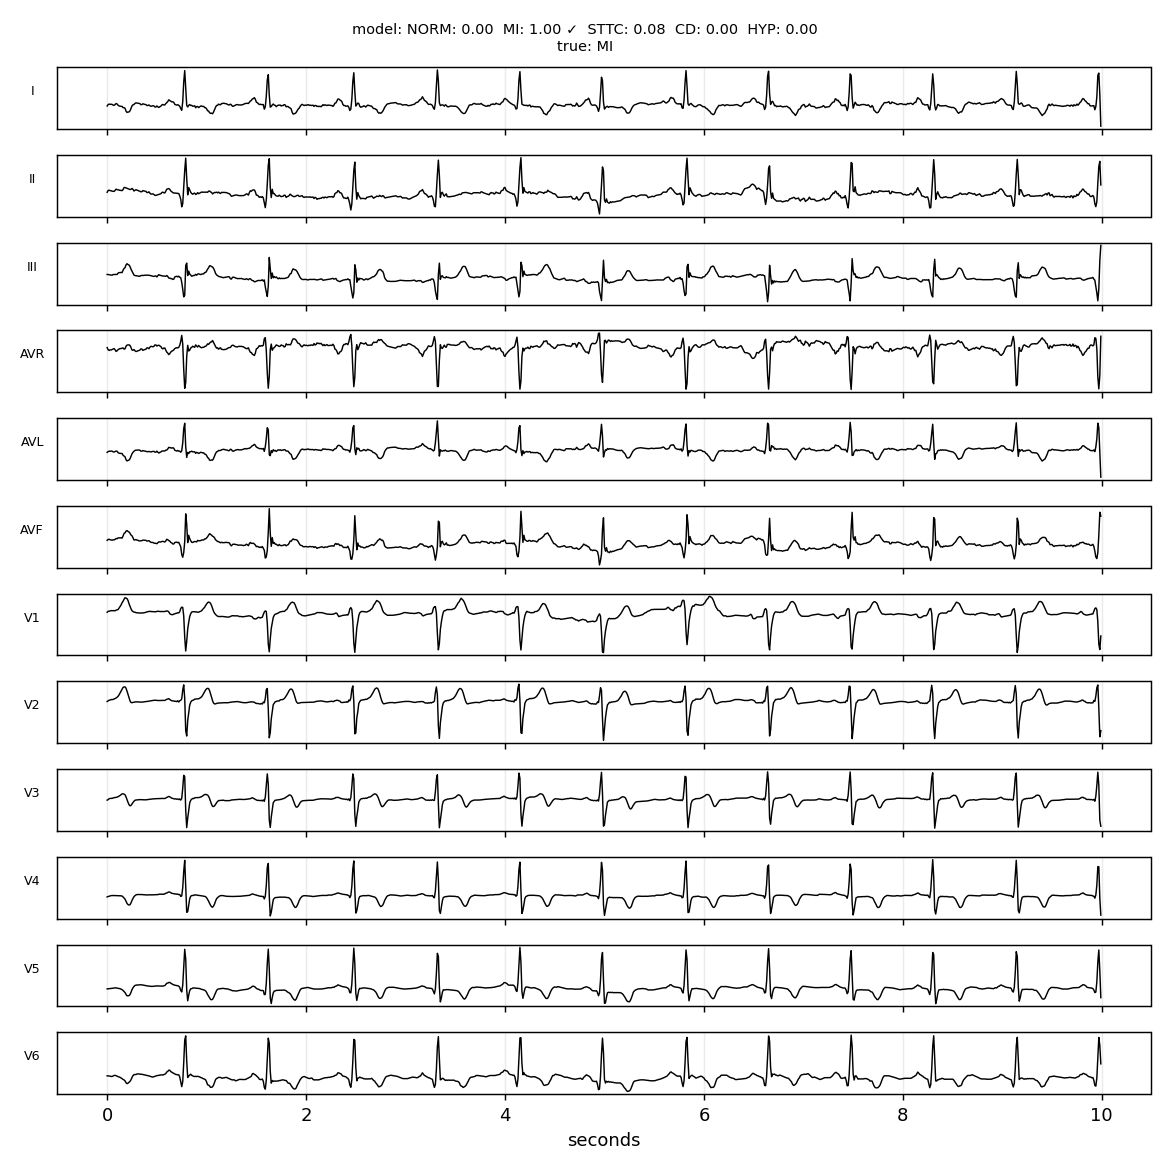

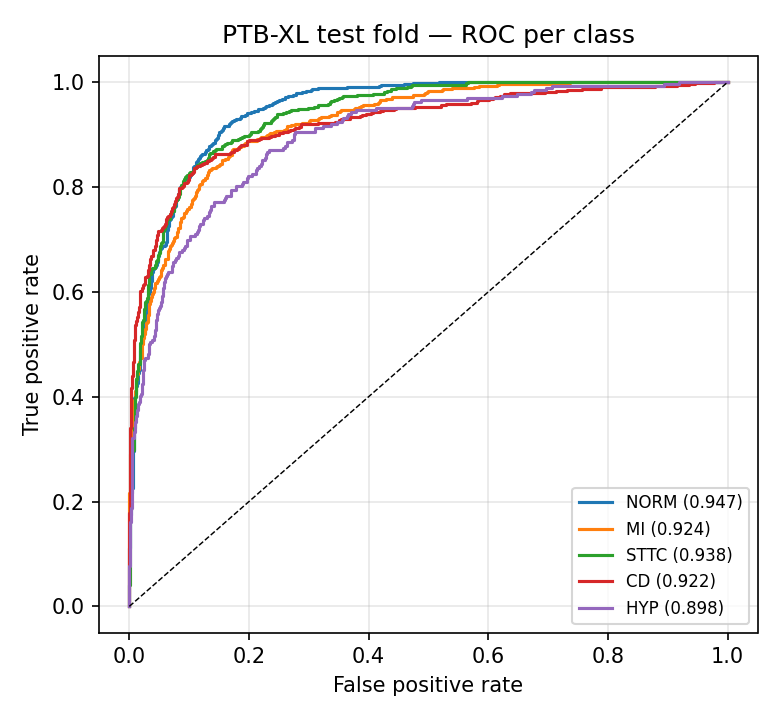

Download /kaggle/working/results_for_github.zip and unzip it at the repo root (docs/, models/, results/).


In [26]:
import re, shutil, glob, os
from IPython.display import Markdown, Image, display
w = cfg.work_dir
text = open(f"{w}/results/REPORT.md", encoding="utf-8").read()
display(Markdown(re.sub(r"!\[.*?\]\(figures/.*?\)", "", text)))
for f in sorted(glob.glob(f"{w}/results/figures/*.png")):
    display(Image(f))
pkg = "/kaggle/working/github_package"
shutil.rmtree(pkg, ignore_errors=True)
for sub in ("results", "models"):
    shutil.copytree(f"{w}/{sub}", f"{pkg}/{sub}")
os.makedirs(f"{pkg}/docs", exist_ok=True)
for f in ("model.onnx", "meta.json", "samples.json"):
    shutil.copy(f"{w}/docs/{f}", f"{pkg}/docs/{f}")
shutil.make_archive("/kaggle/working/results_for_github", "zip", pkg)
print("Download /kaggle/working/results_for_github.zip and unzip it at the repo root (docs/, models/, results/).")